<a href="https://colab.research.google.com/github/yeimy07/automated-academic-data-cleaner/blob/main/AnalisisData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Anticiparse al futuro, optimizar el presente  y crear soluciones centradas en las personas y el  impacto.

# Analisis de datos


* definir objetivo y pregunta

# Objetivo general
Desarrollar un modelo automatizado de análisis de datos académicos que optimice la gestión de la información institucional del Centro de los Recursos Naturales Renovables La Salada, como estrategia para fortalecer la toma de decisiones y promover la innovación tecnológica local.

# Pregunta

¿Cómo puede la implementación de un modelo automatizado de análisis de datos optimizar el procesamiento, la organización y la interpretación de la información académica (PE-04 y DF-14) del Centro de los Recursos Naturales Renovables La Salada, para fortalecer la toma de decisiones institucionales y promover la adopción tecnológica local?


* Recopilación de los datos

In [ ]:
# Se importan todas librería necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files # Permite cargar los excels
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
# from google.colab import files # Permite cargar los excels. Comentado si se ejecuta localmente.
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Configuración de los estilos del graficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12




In [ ]:
Uploaded = files.upload() # Permite cargar el excel PE-04


Saving B2.xlsx to B2.xlsx


In [ ]:
Uploaded = files.upload() # Permite cargar el excel DF-14

Saving B1.xlsx to B1.xlsx


In [ ]:


try:
    # Carga de B1 (Matriculados)
    df_matriculados = pd.read_excel("B1.xlsx", header=4)
    # Carga de B2 (Programación)
    df_programacion = pd.read_excel("B2.xlsx", header=4)
    print(" Datos cargados correctamente.")
except FileNotFoundError:
    print("ERROR: Asegúrate de que los archivos excel estén en el directorio de trabajo.")
    exit()

 Datos cargados correctamente.


 * Limpieza y procesamiento

In [ ]:
# Funciones para la limpieza y reprocesamiento

def limpiar_texto(df, columna):
    """Limpia y estandariza el texto de una columna."""
    df[columna] = df[columna].astype(str).str.upper().str.strip()
    return df

def limpieza_general(df):
    """Aplica limpieza general (texto, duplicados)."""
    # Eliminar filas completamente duplicadas
    df.drop_duplicates(inplace=True)

    # Estandarizar nombres de columnas eliminando espacios y caracteres especiales
    df.columns = df.columns.str.strip().str.replace('[^A-Za-z0-9_]+', '', regex=True).str.upper()

    return df


In [ ]:
import pandas as pd # Ensure pandas is imported

# Ensure df_matriculados is loaded if it's not already a DataFrame or was reset
if 'df_matriculados' not in locals() or not isinstance(df_matriculados, pd.DataFrame):
    try:
        df_matriculados = pd.read_excel("B1.xlsx", header=4)
        print(" df_matriculados re-cargado correctamente para limpieza.")
    except FileNotFoundError:
        print("ERROR: 'B1.xlsx' no encontrado. Asegúrate de que el archivo esté en el directorio de trabajo.")
        exit()

#--- 3. Limpieza Específica por Archivo ---

## B1: Limpieza del Reporte de Matriculados
df_matriculados = limpieza_general(df_matriculados)

# Columnas clave para estandarización de texto
# Using correct standardized column names (with underscores preserved by limpieza_general)
for col in ['SEDE', 'REGIONAL', 'PROGRAMA', 'NIVEL_DE_FORMACION', 'ESTADO_APRENDIZ']:
    df_matriculados = limpiar_texto(df_matriculados, col)

# Relleno de valores nulos (estrategia de "NO APLICA" para datos de empresa/convenio)
cols_empresa_convenio = [
    'IDENTIFICADOR_CONVENIO', 'CONVENIO', 'TIPO_DOCUMENTO_EMPRESA',
    'NUMERO_DOCUMENTO_EMPRESA', 'EMPRESA'
]
df_matriculados[cols_empresa_convenio] = df_matriculados[cols_empresa_convenio].fillna('NO APLICA')

# Rellenar 'AMPLIACION_COVERTURA' (asumiendo que nulo significa NO)
# Corrected 'AMPLIACION_COBERTURA' to 'AMPLIACION_COVERTURA' (with V)
df_matriculados['AMPLIACION_COVERTURA'] = df_matriculados['AMPLIACION_COVERTURA'].fillna('NO')
df_matriculados = limpiar_texto(df_matriculados, 'AMPLIACION_COVERTURA')

print("\n Reporte de Matriculados limpio.")


## 🧹 B2: Limpieza del Reporte de Programación
df_programacion = limpieza_general(df_programacion)

# Columnas clave para estandarización de texto
# Using correct standardized column names (with underscores preserved by limpieza_general)
for col in ['NOMBRE_REGIONAL', 'NOMBRE_CENTRO', 'NIVEL_FORMACION', 'NOMBRE_JORNADA', 'NOMBRE_PROGRAMA_FORMACION']:
    df_programacion = limpiar_texto(df_programacion, col)

# Relleno de valores nulos para datos de convenios y programas especiales
cols_convenio_esp = ['CODIGO_CONVENIO', 'NOMBRE_CONVENIO', 'CODIGO_PROGRAMA_ESPECIAL']
df_programacion[cols_convenio_esp] = df_programacion[cols_convenio_esp].fillna('SIN CONVENIO')

# Rellenar 'AMPLIACION_COBERTURA' (asumiendo que nulo significa NO)
df_programacion['AMPLIACION_COBERTURA'] = df_programacion['AMPLIACION_COBERTURA'].fillna('NO')
df_programacion = limpiar_texto(df_programacion, 'AMPLIACION_COBERTURA')

# Convertir fechas a tipo datetime
df_programacion['FECHA_INICIO_FICHA'] = pd.to_datetime(df_programacion['FECHA_INICIO_FICHA'], errors='coerce', format='%d/%m/%Y')
df_programacion['FECHA_TERMINACION_FICHA'] = pd.to_datetime(df_programacion['FECHA_TERMINACION_FICHA'], errors='coerce', format='%d/%m/%Y')

print(" Reporte de Programación limpio.")


 Reporte de Matriculados limpio.
 Reporte de Programación limpio.


# Analisis exploratorio y estadístico


--- Estadísticos Descriptivos para la Población de Aprendices (df_programacion) ---

--- Columna: TOTAL_APRENDICES ---
  Media: 26.10
  Mediana: 19.00
  Moda: 15.00
  Desviación Estándar: 19.79
  Varianza: 391.50
  Asimetría: 2.92
  Curtosis: 15.62

--- Columna: TOTAL_APRENDICES_MASCULINOS ---
  Media: 9.73
  Mediana: 8.00
  Moda: 8.00
  Desviación Estándar: 9.37
  Varianza: 87.73
  Asimetría: 3.28
  Curtosis: 27.46

--- Columna: TOTAL_APRENDICES_FEMENINOS ---
  Media: 15.93
  Mediana: 12.00
  Moda: 7.00
  Desviación Estándar: 13.63
  Varianza: 185.88
  Asimetría: 1.93
  Curtosis: 4.63

--- Columna: TOTAL_APRENDICES_NOBINARIO ---
  Media: 0.43
  Mediana: 0.00
  Moda: 0.00
  Desviación Estándar: 2.01
  Varianza: 4.06
  Asimetría: 9.46
  Curtosis: 140.58

--- Resumen Estadístico Comparativo ---
|                             |   Media |   Mediana |   Moda |   Desviación Estándar |   Varianza |   Asimetría (Skew) |   Curtosis (Kurt) |
|:----------------------------|--------:|----------:|-

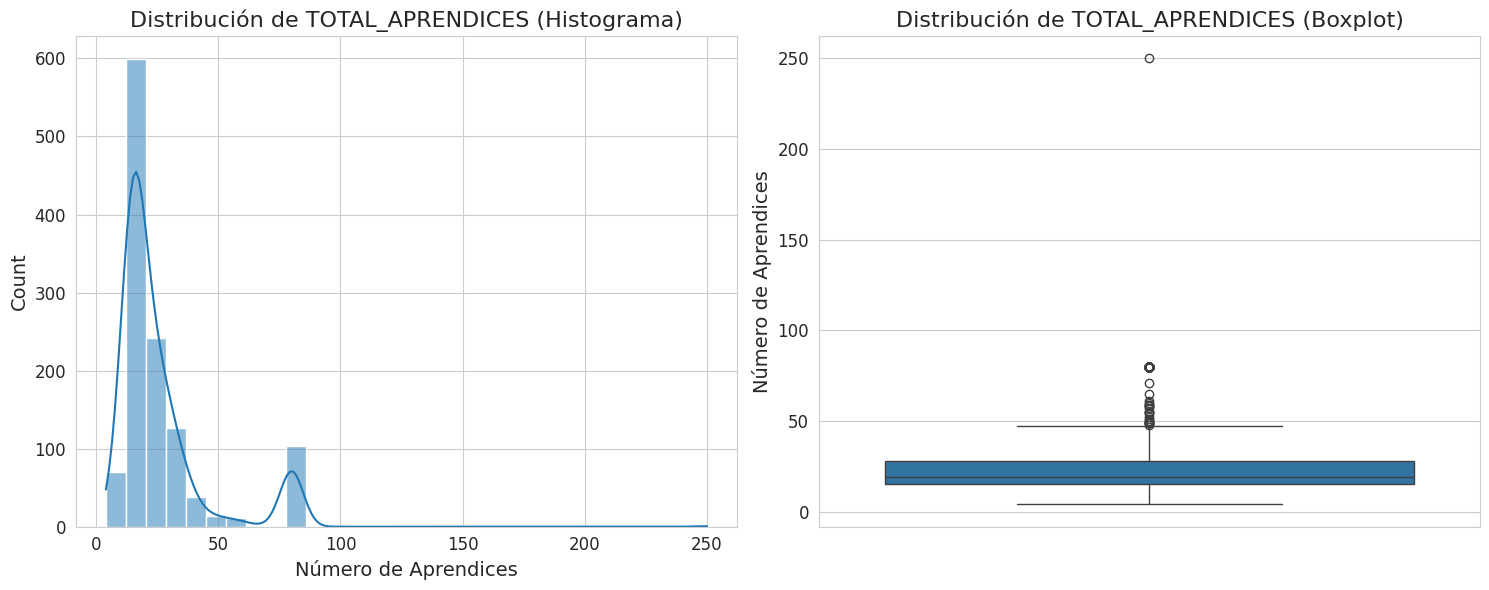

In [ ]:
# Calculamos la media, mediana, moda, desviación estandar, varianza, asimetrría, curtosis

#  Análisis Descriptivo de las Variables de Aprendices

variables_aprendices = [
    'TOTAL_APRENDICES',
    'TOTAL_APRENDICES_MASCULINOS',
    'TOTAL_APRENDICES_FEMENINOS',
    'TOTAL_APRENDICES_NOBINARIO'
]

# Asegurar que las columnas sean de tipo numérico, forzando errores a NaN
for col in variables_aprendices:
    # Se utiliza errors='coerce' para convertir cualquier valor no numérico a NaN
    # y luego se rellena con 0 para este análisis (asumiendo que un nulo significa 0 aprendices de ese tipo)
    df_programacion[col] = pd.to_numeric(df_programacion[col], errors='coerce').fillna(0)

print("\n--- Estadísticos Descriptivos para la Población de Aprendices (df_programacion) ---")

resultados_estadisticos = {}

for col in variables_aprendices:
    print(f"\n--- Columna: {col} ---")

    data = df_programacion[col]

    media = data.mean()
    mediana = data.median()
    moda = data.mode().iloc[0] if not data.mode().empty else None
    desviacion_estandar = data.std()
    varianza = data.var()
    asimetria = data.skew()
    curtosis = data.kurt()

    resultados_estadisticos[col] = {
        'Media': media,
        'Mediana': mediana,
        'Moda': moda,
        'Desviación Estándar': desviacion_estandar,
        'Varianza': varianza,
        'Asimetría (Skew)': asimetria,
        'Curtosis (Kurt)': curtosis
    }

    print(f"  Media: {media:.2f}")
    print(f"  Mediana: {mediana:.2f}")
    print(f"  Moda: {moda:.2f}")
    print(f"  Desviación Estándar: {desviacion_estandar:.2f}")
    print(f"  Varianza: {varianza:.2f}")
    print(f"  Asimetría: {asimetria:.2f}")
    print(f"  Curtosis: {curtosis:.2f}")


# 4.3. Visualización de los resultados en una tabla comparativa
df_resultados = pd.DataFrame(resultados_estadisticos).T
print("\n--- Resumen Estadístico Comparativo ---")
print(df_resultados.to_markdown(floatfmt=".2f"))


# Generar un histograma para  'TOTAL_APRENDICES'
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
sns.histplot(df_programacion['TOTAL_APRENDICES'], kde=True, bins=30)
plt.title('Distribución de TOTAL_APRENDICES (Histograma)')
plt.xlabel('Número de Aprendices')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_programacion['TOTAL_APRENDICES'])
plt.title('Distribución de TOTAL_APRENDICES (Boxplot)')
plt.ylabel('Número de Aprendices')

plt.tight_layout()
plt.show()




 Datos cruzados correctamente. Dimensión: (33259, 74)

--- Estadísticos Descriptivos ---


/tmp/ipython-input-1517220889.py:91: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


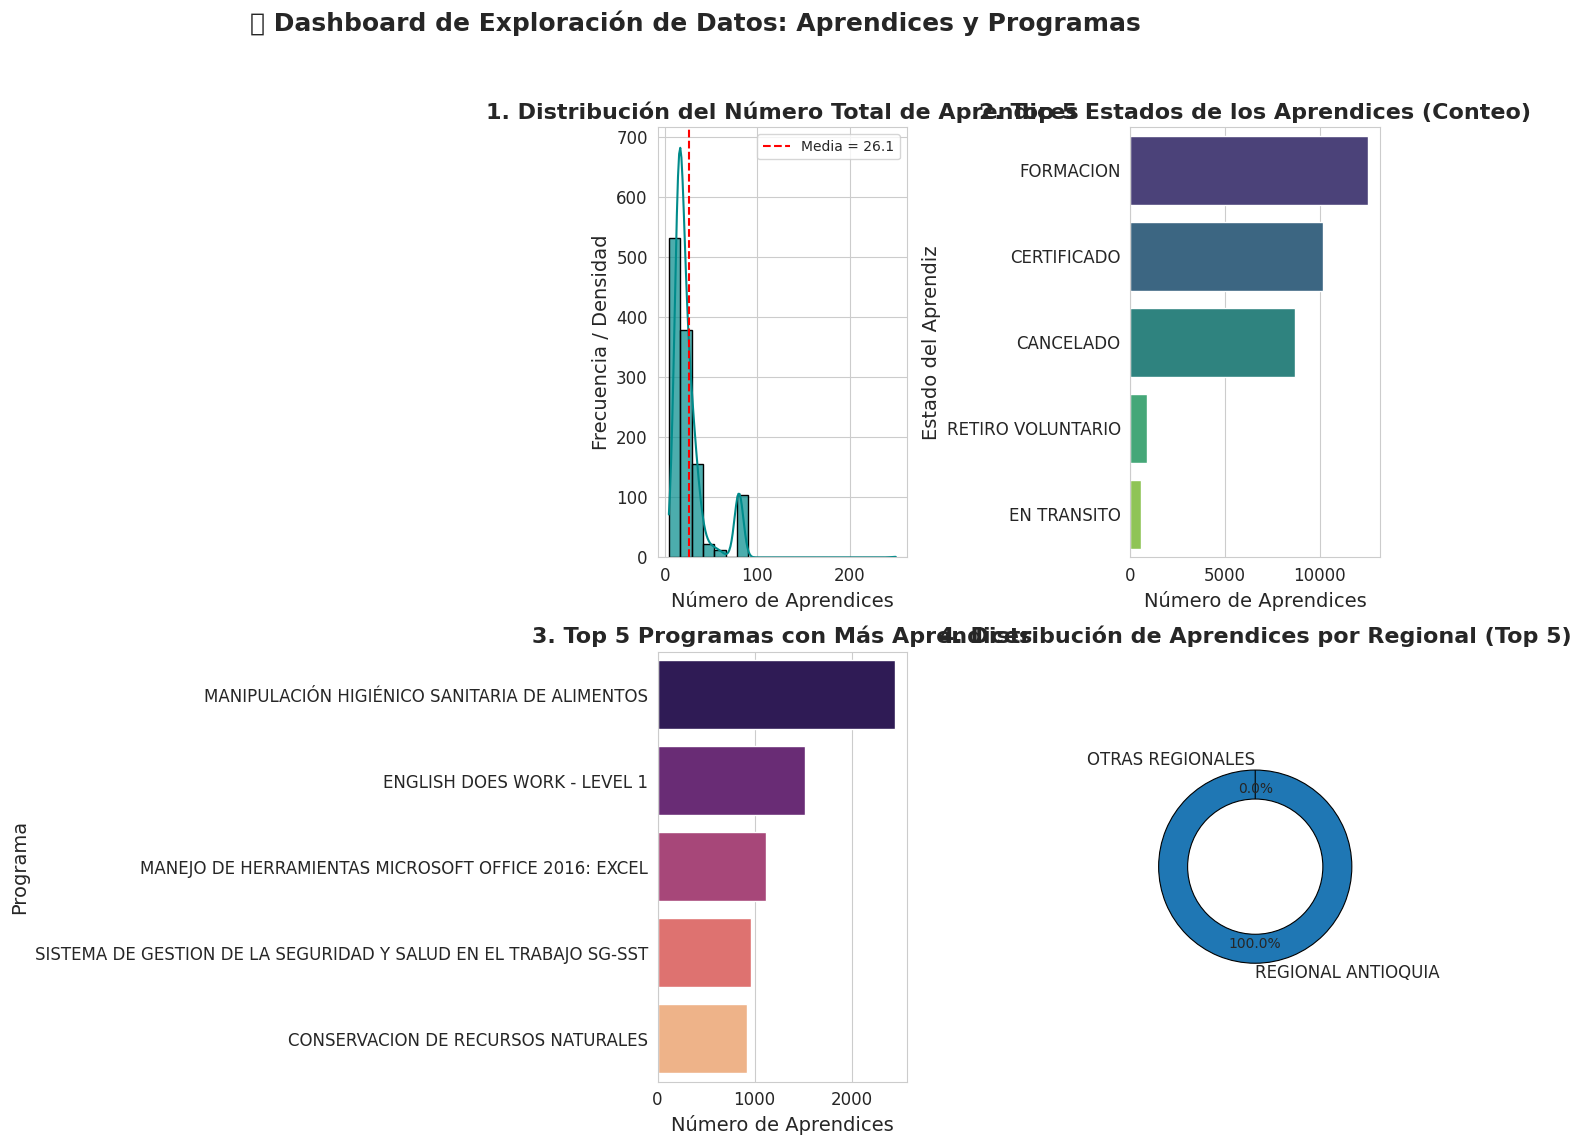


--- Análisis de Eficiencia por Regional ---


/tmp/ipython-input-1517220889.py:124: UserWarning: Glyph 128285 (\N{TOP WITH UPWARDS ARROW ABOVE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.03, 1, 0.9])
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128285 (\N{TOP WITH UPWARDS ARROW ABOVE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


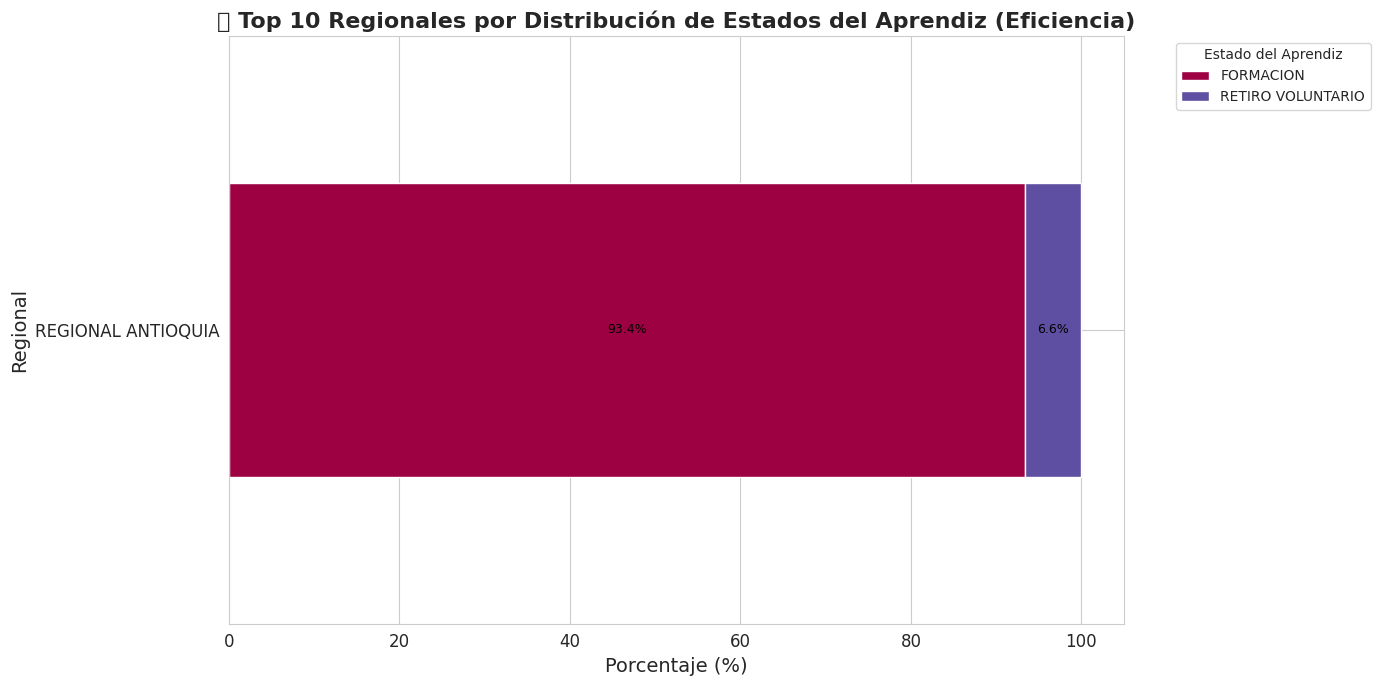



6. ANÁLISIS DE REGRESIÓN MÚLTIPLE

--- Resumen del Modelo de Regresión Lineal Múltiple ---
                             OLS Regression Results                            
Dep. Variable:     Duracion_Ficha_Dias   R-squared:                       0.003
Model:                             OLS   Adj. R-squared:                  0.001
Method:                  Least Squares   F-statistic:                     1.762
Date:                 Thu, 27 Nov 2025   Prob (F-statistic):              0.172
Time:                         19:54:09   Log-Likelihood:                -8392.3
No. Observations:                 1203   AIC:                         1.679e+04
Df Residuals:                     1200   BIC:                         1.681e+04
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
---------------

/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
/tmp/ipython-input-1517220889.py:222: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels(['Otras Modalidades', 'Presencial'])
/tmp/ipython-input-1517220889.py:238: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


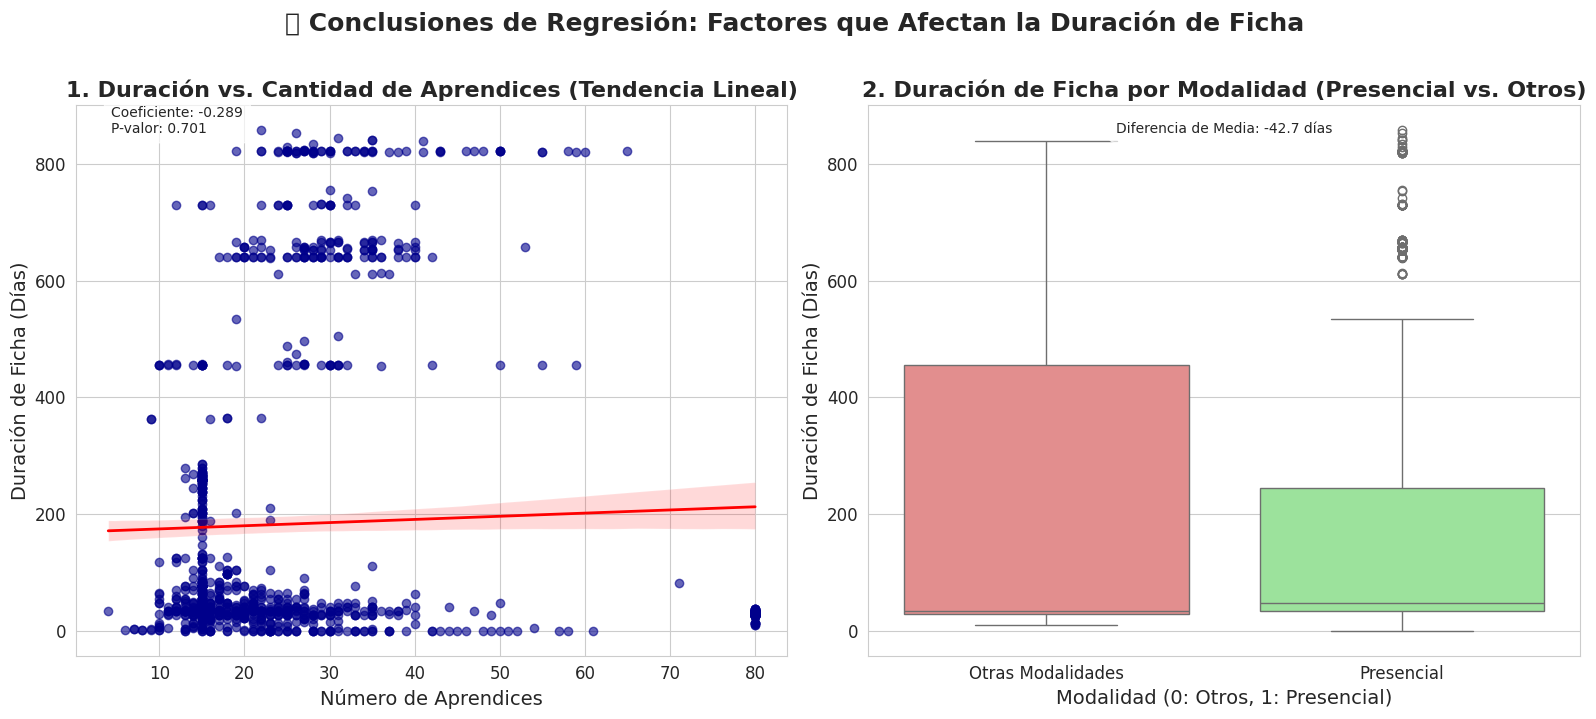


FIN DEL ANÁLISIS


In [ ]:
# --- 4. Cruce de Información (Merge) ---

# Renombrar columna en B1 para un cruce claro
df_matriculados.rename(columns={'FICHA': 'IDENTIFICADOR_FICHA_CRUCE'}, inplace=True)

# Convertir la columna de cruce a entero si es posible, ya que son códigos
try:
    df_matriculados['IDENTIFICADOR_FICHA_CRUCE'] = pd.to_numeric(df_matriculados['IDENTIFICADOR_FICHA_CRUCE'], errors='coerce').astype('Int64')
    df_programacion['IDENTIFICADOR_FICHA'] = pd.to_numeric(df_programacion['IDENTIFICADOR_FICHA'], errors='coerce').astype('Int64')
except:
    print("\n Advertencia: No se pudo convertir el código de ficha a entero. Se cruza como string.")


df_cruzado = pd.merge(
    df_matriculados,
    df_programacion,
    left_on='IDENTIFICADOR_FICHA_CRUCE',
    right_on='IDENTIFICADOR_FICHA',
    how='left',
    suffixes=('_APRENDIZ', '_CURSO')
)
print(f"\n Datos cruzados correctamente. Dimensión: {df_cruzado.shape}")

# --- 4. Análisis Descriptivo (Con Gráficos Mejorados) ---
variables_aprendices = [
    'TOTAL_APRENDICES',
    'TOTAL_APRENDICES_MASCULINOS',
    'TOTAL_APRENDICES_FEMENINOS',
    'TOTAL_APRENDICES_NOBINARIO'
]
for col in variables_aprendices:
    df_programacion[col] = pd.to_numeric(df_programacion[col], errors='coerce').fillna(0)

print("\n--- Estadísticos Descriptivos ---")

# --- Dashboard 1: Distribución y Conteo ---
fig, axs = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('📊 Dashboard de Exploración de Datos: Aprendices y Programas', fontsize=18, fontweight="bold", y=0.98)

# Gráfico 1: Distribución de TOTAL_APRENDICES (Histograma y Densidad)
sns.histplot(df_programacion['TOTAL_APRENDICES'], kde=True, bins=20, color="darkcyan", alpha=0.7, ax=axs[0, 0], edgecolor='black')
mu = df_programacion['TOTAL_APRENDICES'].mean()
axs[0, 0].axvline(mu, color='red', linestyle='--', linewidth=1.5, label=f'Media = {mu:.1f}')
axs[0, 0].set_title('1. Distribución del Número Total de Aprendices', fontweight='bold')
axs[0, 0].set_xlabel('Número de Aprendices')
axs[0, 0].set_ylabel('Frecuencia / Densidad')
axs[0, 0].legend()

# Gráfico 2: Distribución de Estados de Aprendices (Conteo)
estado_counts = df_matriculados['ESTADO_APRENDIZ'].value_counts().head(5)
sns.barplot(
    x=estado_counts.values,
    y=estado_counts.index,
    palette='viridis',
    ax=axs[0, 1]
)
axs[0, 1].set_title('2. Top 5 Estados de los Aprendices (Conteo)', fontweight='bold')
axs[0, 1].set_xlabel('Número de Aprendices')
axs[0, 1].set_ylabel('Estado del Aprendiz')

# Gráfico 3: Top 5 Programas con Mayor Número de Aprendices
programa_counts = df_matriculados['PROGRAMA'].value_counts().head(5)
sns.barplot(x=programa_counts.values, y=programa_counts.index, palette='magma', ax=axs[1, 0])
axs[1, 0].set_title('3. Top 5 Programas con Más Aprendices', fontweight='bold')
axs[1, 0].set_xlabel('Número de Aprendices')
axs[1, 0].set_ylabel('Programa')

# Gráfico 4: Aprendices por Regional (Gráfico de Torta con estilo)
regional_counts = df_matriculados['REGIONAL'].value_counts().head(5)
other_count = df_matriculados['REGIONAL'].value_counts().sum() - regional_counts.sum()
final_counts = pd.concat([regional_counts, pd.Series([other_count], index=['OTRAS REGIONALES'])])

axs[1, 1].pie(
    final_counts,
    labels=final_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("tab20", len(final_counts)),
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8},
    pctdistance=0.8
)
centre_circle = plt.Circle((0,0), 0.70, fc='white', edgecolor='black', linewidth=0.8)
axs[1, 1].add_artist(centre_circle)
axs[1, 1].set_title('4. Distribución de Aprendices por Regional (Top 5)', fontweight='bold')
axs[1, 1].axis('equal') # Asegura que sea un círculo
# Quitar etiquetas de los ejes
axs[1, 1].set_xlabel("")
axs[1, 1].set_ylabel("")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


# --- 5. Análisis de Eficiencia por Regional (Gráfico de Barras Apiladas Mejorado) ---
print("\n--- Análisis de Eficiencia por Regional ---")
estados_interes = ['RETIRO VOLUNTARIO', 'FORMACION', 'TERMINADA POR FECHA']
df_eficiencia = df_cruzado[df_cruzado['ESTADO_APRENDIZ'].isin(estados_interes)].copy()
contingency_regional = pd.crosstab(
    df_eficiencia['REGIONAL'],
    df_eficiencia['ESTADO_APRENDIZ'],
    normalize='index'
).mul(100).sort_values(by='RETIRO VOLUNTARIO', ascending=False)
top_10_regionales = contingency_regional.head(10)

plt.figure(figsize=(14, 8))
# Usar un colormap más contrastado y con énfasis en el Retiro
ax = top_10_regionales.plot(
    kind='barh',
    stacked=True,
    colormap='Spectral', # Colores contrastantes
    ax=plt.gca()
)
ax.set_title('🔝 Top 10 Regionales por Distribución de Estados del Aprendiz (Eficiencia)', fontsize=16, fontweight='bold')
ax.set_xlabel('Porcentaje (%)', fontsize=14)
ax.set_ylabel('Regional', fontsize=14)
ax.legend(title='Estado del Aprendiz', bbox_to_anchor=(1.05, 1), loc='upper left')

# Añadir etiquetas de porcentaje dentro de las barras para una lectura rápida
for c in ax.containers:
    labels = [f'{v.get_width():.1f}%' if v.get_width() > 3 else '' for v in c]
    ax.bar_label(c, labels=labels, label_type='center', fontsize=9, color='black')

plt.tight_layout(rect=[0, 0.03, 1, 0.9])
plt.show()

# =========================================================================
# --- 6. Análisis de Regresión Múltiple ---
# =========================================================================

print("\n\n" + "="*50)
print("6. ANÁLISIS DE REGRESIÓN MÚLTIPLE")
print("="*50)

### Variables Definidas:
# DEPENDIENTE (Y): Duracion_Ficha_Dias (numérica, continua)
# INDEPENDIENTES (X): Num_Aprendices (numérica), Modalidad_Presencial (dummy), Ampliacion_Cobertura_SI (dummy)

# --- 6.1. Preparación de Datos para Regresión ---

# 1. Variable Dependiente (Y): Duración de la Ficha (en días)
df_programacion['Duracion_Ficha_Dias'] = (df_programacion['FECHA_TERMINACION_FICHA'] - df_programacion['FECHA_INICIO_FICHA']).dt.days
df_regresion_b2 = df_programacion.dropna(subset=['Duracion_Ficha_Dias'])
df_regresion_b2 = df_regresion_b2[df_regresion_b2['Duracion_Ficha_Dias'] > 0].copy()

# 2. Variable Independiente (X1): Conteo de Aprendices por Ficha
conteo_aprendices = df_matriculados.groupby('IDENTIFICADOR_FICHA_CRUCE').size().reset_index(name='Num_Aprendices')
conteo_aprendices.rename(columns={'IDENTIFICADOR_FICHA_CRUCE': 'IDENTIFICADOR_FICHA'}, inplace=True)

# 3. Variable Independiente (X2, X3): Dummies
# Moda de Modalidad de Formación y Ampliación de Cobertura a nivel Ficha
modalidad_ficha = df_programacion.groupby('IDENTIFICADOR_FICHA')['MODALIDAD_FORMACION'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else 'NO ESPECIFICADO').reset_index()
cobertura_ficha = df_programacion.groupby('IDENTIFICADOR_FICHA')['AMPLIACION_COBERTURA'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else 'NO').reset_index()

# 4. Unión de variables
df_regresion = pd.merge(df_regresion_b2[['IDENTIFICADOR_FICHA', 'Duracion_Ficha_Dias']], modalidad_ficha, on='IDENTIFICADOR_FICHA', how='inner')
df_regresion = pd.merge(df_regresion, cobertura_ficha, on='IDENTIFICADOR_FICHA', how='inner')
df_regresion = pd.merge(df_regresion, conteo_aprendices, on='IDENTIFICADOR_FICHA', how='inner')
df_regresion.drop_duplicates(subset=['IDENTIFICADOR_FICHA'], inplace=True) # Asegurar una fila por ficha

# 5. Creación de Dummies
df_regresion['Modalidad_Presencial'] = df_regresion['MODALIDAD_FORMACION'].apply(lambda x: 1 if x == 'PRESENCIAL' else 0)
df_regresion['Ampliacion_Cobertura_SI'] = df_regresion['AMPLIACION_COBERTURA'].apply(lambda x: 1 if x == 'SI' else 0)


# --- 6.2. Modelo OLS (Ordinary Least Squares) ---

# Definición de Variables Finales
Y = df_regresion['Duracion_Ficha_Dias']
X = df_regresion[['Num_Aprendices', 'Modalidad_Presencial', 'Ampliacion_Cobertura_SI']]

# Agregar la constante para el intercepto
X = sm.add_constant(X)

# Dividir para validación (opcional, pero buena práctica)
# X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Entrenar el modelo con todos los datos disponibles
modelo_ols = sm.OLS(Y, X).fit()

print("\n--- Resumen del Modelo de Regresión Lineal Múltiple ---")
print(modelo_ols.summary())


# --- 6.3. Gráficas de Conclusión de Regresión (Estilo Dashboard) ---

fig, axs = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('✨ Conclusiones de Regresión: Factores que Afectan la Duración de Ficha', fontsize=18, fontweight="bold", y=1.02)

# Gráfico 1: Relación entre Num_Aprendices y Duracion_Ficha_Dias
sns.regplot(
    x='Num_Aprendices',
    y='Duracion_Ficha_Dias',
    data=df_regresion,
    scatter_kws={'alpha': 0.6, 'color': 'darkblue'},
    line_kws={'color': 'red', 'linewidth': 2},
    ax=axs[0]
)
axs[0].set_title('1. Duración vs. Cantidad de Aprendices (Tendencia Lineal)', fontweight='bold')
axs[0].set_xlabel('Número de Aprendices')
axs[0].set_ylabel('Duración de Ficha (Días)')
axs[0].text(
    0.05, 0.95,
    f'Coeficiente: {modelo_ols.params["Num_Aprendices"]:.3f}\nP-valor: {modelo_ols.pvalues["Num_Aprendices"]:.3f}',
    transform=axs[0].transAxes,
    bbox=dict(boxstyle="round,pad=0.5", fc="white", alpha=0.7)
)
#


# Gráfico 2: Efecto de la Modalidad sobre la Duración (Boxplot)
sns.boxplot(
    x='Modalidad_Presencial',
    y='Duracion_Ficha_Dias',
    data=df_regresion,
    palette=['lightcoral', 'lightgreen'],
    ax=axs[1]
)
axs[1].set_title('2. Duración de Ficha por Modalidad (Presencial vs. Otros)', fontweight='bold')
axs[1].set_xlabel('Modalidad (0: Otros, 1: Presencial)')
axs[1].set_ylabel('Duración de Ficha (Días)')
axs[1].set_xticklabels(['Otras Modalidades', 'Presencial'])

# Añadir la diferencia de medias como etiqueta
mean_presencial = df_regresion[df_regresion['Modalidad_Presencial'] == 1]['Duracion_Ficha_Dias'].mean()
mean_otros = df_regresion[df_regresion['Modalidad_Presencial'] == 0]['Duracion_Ficha_Dias'].mean()
diff = mean_presencial - mean_otros

axs[1].text(
    0.5, 0.95,
    f'Diferencia de Media: {diff:.1f} días',
    ha='center',
    transform=axs[1].transAxes,
    bbox=dict(boxstyle="round,pad=0.5", fc="white", alpha=0.7)
)
#

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("FIN DEL ANÁLISIS")
print("="*50)

Conclusiones

1. Fuerte Asimetría Positiva (Sesgo a la Derecha)La distribución de TOTAL_APRENDICES presenta una alta asimetría positiva ($\text{Asimetría} > 1.0$). Esto significa que la mayor parte de la programación se concentra en un número bajo de aprendices por ficha (la moda y la mediana son bajas), pero la existencia de un número reducido de fichas excepcionalmente grandes genera una cola derecha larga, sesgando fuertemente el promedio.

2. Heterogeneidad en el Tamaño de las FichasLa alta Desviación Estándar ($\sigma$) y la Varianza indican que existe una gran dispersión en la variable. Los tamaños de las fichas de programación no son homogéneos, variando drásticamente desde eventos con muy pocos participantes hasta programas troncales con el cupo máximo o convenios masivos.

3. Falta de Representatividad de la MediaDebido a la marcada asimetría y dispersión, el valor de la Media no es un buen indicador del tamaño típico de una ficha. La Mediana, al ser menos sensible a los valores extremos (outliers), representa un indicador más robusto y fiel del tamaño más frecuente o central de la programación.

4. Distribución Leptocúrtica y Presencia de OutliersEl valor de la Curtosis de Fisher es positivo y alto ($\text{Curtosis} > 0$), lo que clasifica la distribución como leptocúrtica. Esto implica que los datos están altamente concentrados en un pico estrecho (fichas pequeñas) y, simultáneamente, presentan colas más pesadas que una distribución normal. Esta pesadez de las colas se debe a la significativa cantidad de valores atípicos (outliers) que se observan en el boxplot.

5. Identificación de Fichas Masivas como Factores ClaveEl boxplot revela una gran cantidad de puntos de datos individuales muy por encima del límite superior del bigote. Estas son las fichas de programación con la mayor concentración de aprendices. Estos outliers deben ser investigados, ya que representan programas de alto impacto o convenios específicos que son críticos para el cumplimiento de las metas de cobertura.


 Datos cruzados correctamente en 'df_cruzado'.
Dimensión del DataFrame Cruzado: (33259, 74)


/tmp/ipython-input-3423043602.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


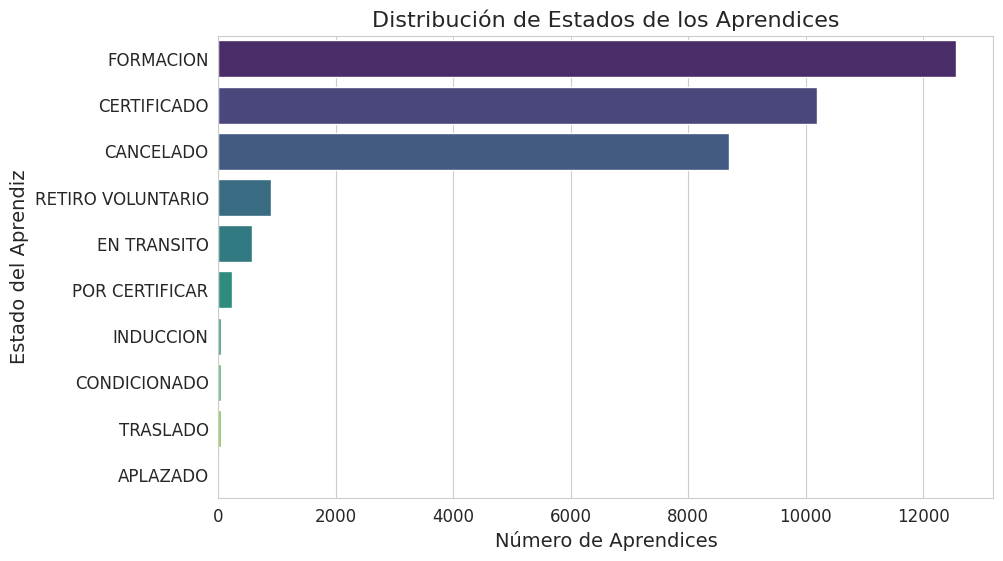

/tmp/ipython-input-3423043602.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=programa_counts.values, y=programa_counts.index, palette='magma')


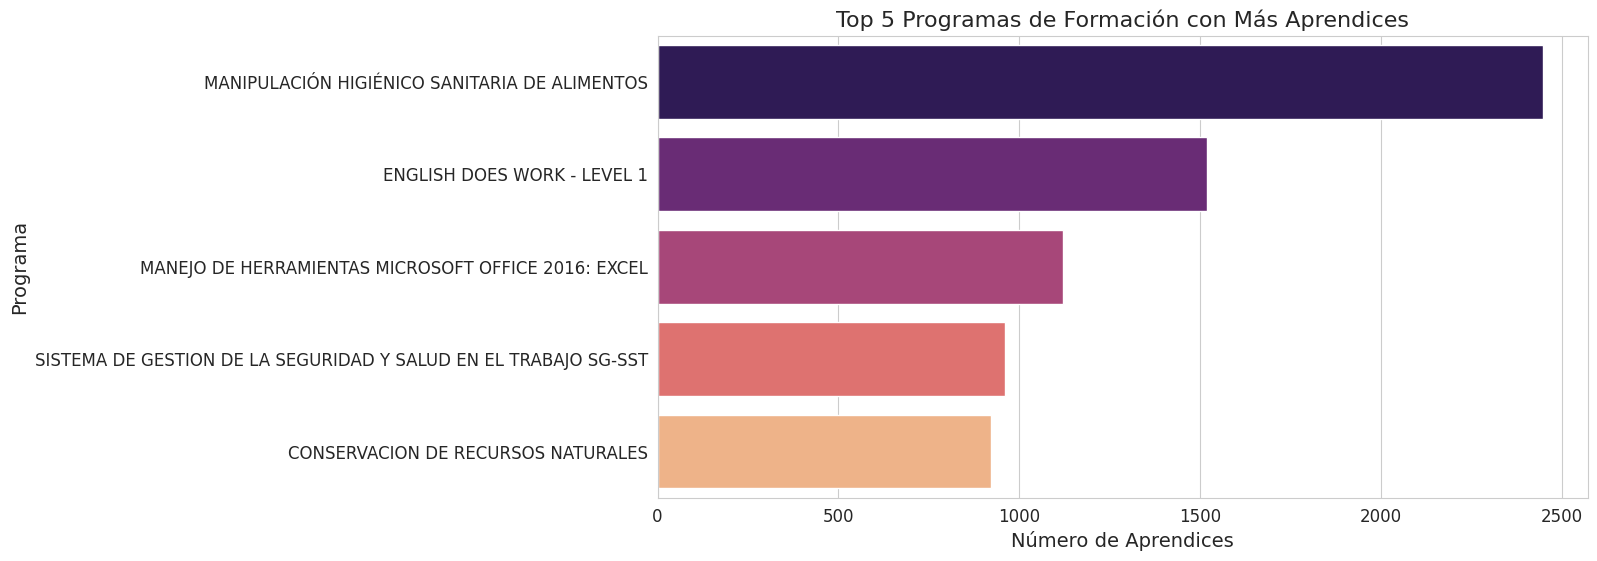

Columnas de df_cruzado antes de limpiar_texto para nivel y modalidad:
Index(['CODIGO_SEDE', 'SEDE', 'CODIGO_REGIONAL_APRENDIZ', 'REGIONAL',
       'IDENTIFICADOR_FICHA_CRUCE', 'ESTADO_FICHA', 'CODIGO_PROGRAMA_APRENDIZ',
       'VERSION_PROGRANA', 'PROGRAMA', 'NIVEL_DE_FORMACION', 'TIPO_DOCUMENTO',
       'NUMERO_DOCUMENTO', 'NOMBRE', 'PRIMER_APELLIDO', 'SEGUNDO_APELLIDO',
       'ESTADO_APRENDIZ', 'IDENTIFICADOR_CONVENIO', 'AMPLIACION_COVERTURA',
       'CONVENIO', 'TIPO_DOCUMENTO_EMPRESA', 'NUMERO_DOCUMENTO_EMPRESA',
       'EMPRESA', 'CODIGO_REGIONAL_CURSO', 'NOMBRE_REGIONAL', 'CODIGO_CENTRO',
       'NOMBRE_CENTRO', 'IDENTIFICADOR_FICHA', 'IDENTIFICADOR_UNICO_FICHA',
       'ESTADO_CURSO', 'CODIGO_NIVEL_FORMACION', 'NIVEL_FORMACION',
       'CODIGO_JORNADA', 'NOMBRE_JORNADA', 'TIPO_DE_FORMACION',
       'FECHA_INICIO_FICHA', 'FECHA_TERMINACION_FICHA', 'ETAPA_FICHA',
       'MODALIDAD_FORMACION', 'NOMBRE_RESPONSABLE',
       'NUMERO_IDENTIFICACION_EMPRESA', 'TIPO_IDENTIFICACION_EMPRE

<Figure size 1200x700 with 0 Axes>

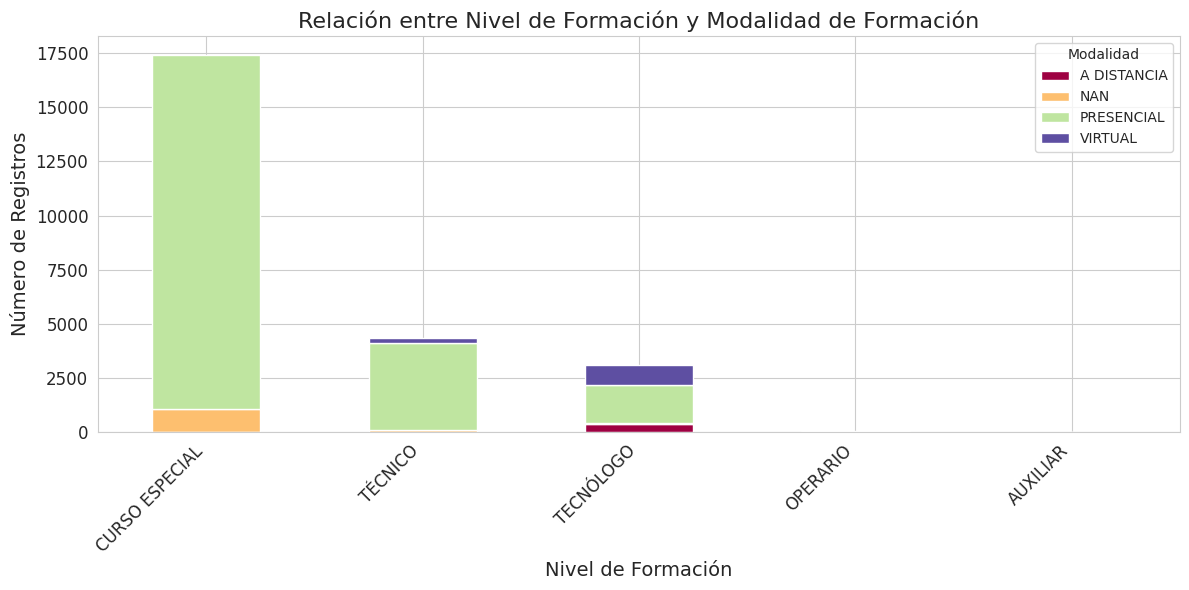

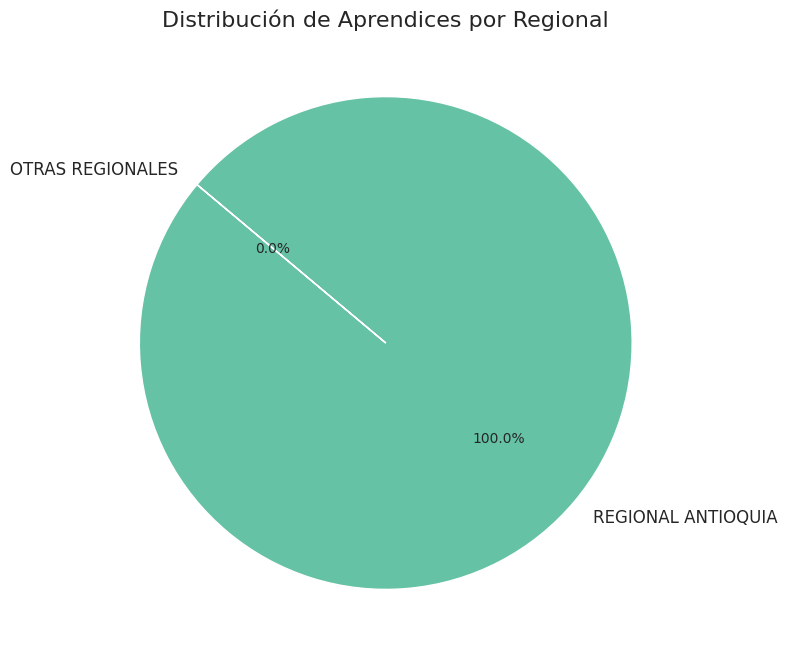

In [ ]:
# --- 4. Cruce de Información (Merge) ---
# El punto de cruce más robusto es el código de ficha, ya que identifica un curso/grupo específico.
# B1 tiene 'FICHA', B2 tiene 'IDENTIFICADOR_FICHA' o 'IDENTIFICADOR_UNICO_FICHA'.
# Asumiremos que B1['FICHA'] y B2['IDENTIFICADOR_FICHA'] son el mismo ID de grupo de formación.

# Renombrar columna en B1 para un cruce claro
df_matriculados.rename(columns={'FICHA': 'IDENTIFICADOR_FICHA_CRUCE'}, inplace=True)

# Convertir la columna de cruce a entero si es posible, ya que son códigos
try:
    df_matriculados['IDENTIFICADOR_FICHA_CRUCE'] = pd.to_numeric(df_matriculados['IDENTIFICADOR_FICHA_CRUCE'], errors='coerce').astype('Int64')
    # Corrected 'IDENTIFICADORFICHA' to 'IDENTIFICADOR_FICHA'
    df_programacion['IDENTIFICADOR_FICHA'] = pd.to_numeric(df_programacion['IDENTIFICADOR_FICHA'], errors='coerce').astype('Int64')
except:
    print("\n Advertencia: No se pudo convertir el código de ficha a entero. Se cruza como string.")


# Cruce Left Join: Mantener todos los registros de aprendices y añadir la información del curso.
df_cruzado = pd.merge(
    df_matriculados,
    df_programacion,
    left_on='IDENTIFICADOR_FICHA_CRUCE',
    right_on='IDENTIFICADOR_FICHA',
    how='left',
    suffixes=('_APRENDIZ', '_CURSO')
)

print("\n Datos cruzados correctamente en 'df_cruzado'.")
print(f"Dimensión del DataFrame Cruzado: {df_cruzado.shape}")

# --- 5. Análisis Exploratorio y Visualizaciones ---

## 5.1. Distribución de Estados de Aprendices
plt.figure(figsize=(10, 6))
sns.countplot(
    y='ESTADO_APRENDIZ',
    data=df_matriculados.replace(' ', np.nan).dropna(subset=['ESTADO_APRENDIZ']), # Limpieza de valores nulos o solo espacios
    order=df_matriculados['ESTADO_APRENDIZ'].value_counts().index,
    palette='viridis'
)
plt.title('Distribución de Estados de los Aprendices')
plt.xlabel('Número de Aprendices')
plt.ylabel('Estado del Aprendiz')
plt.show()
#

## 5.2. Top 5 Programas con Mayor Número de Aprendices
programa_counts = df_matriculados['PROGRAMA'].value_counts().head(5)
plt.figure(figsize=(12, 6))
sns.barplot(x=programa_counts.values, y=programa_counts.index, palette='magma')
plt.title('Top 5 Programas de Formación con Más Aprendices')
plt.xlabel('Número de Aprendices')
plt.ylabel('Programa')
plt.show()
#

## 5.3. Relación entre Nivel de Formación y Modalidad (Usando datos cruzados)
print("Columnas de df_cruzado antes de limpiar_texto para nivel y modalidad:")
print(df_cruzado.columns)

# Limpiar/normalizar la columna de modalidad de formación en df_cruzado
df_cruzado = limpiar_texto(df_cruzado, 'MODALIDAD_FORMACION') # This column name is correct
df_cruzado = limpiar_texto(df_cruzado, 'NIVEL_DE_FORMACION') # Corrected column name

# Agrupar y contar
contingency_table = pd.crosstab(
    df_cruzado['NIVEL_DE_FORMACION'], # Corrected column name
    df_cruzado['MODALIDAD_FORMACION']
).sort_values(by='PRESENCIAL', ascending=False).head(5) # Top 5 niveles

plt.figure(figsize=(12, 7))
contingency_table.plot(kind='bar', stacked=True, colormap='Spectral')
plt.title('Relación entre Nivel de Formación y Modalidad de Formación')
plt.xlabel('Nivel de Formación')
plt.ylabel('Número de Registros')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Modalidad')
plt.tight_layout()
plt.show()
#

## 5.4. Aprendices por Regional (Gráfico de Torta)
regional_counts = df_matriculados['REGIONAL'].value_counts().head(5)
# Se combinan las regionales pequeñas en 'Otras' para una mejor visualización
other_count = df_matriculados['REGIONAL'].value_counts().sum() - regional_counts.sum()
# Use pd.concat instead of append
final_counts = pd.concat([regional_counts, pd.Series([other_count], index=['OTRAS REGIONALES'])])

plt.figure(figsize=(8, 8))
plt.pie(
    final_counts,
    labels=final_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette("Set2", len(final_counts))
)
plt.title('Distribución de Aprendices por Regional')
plt.show()
#


--- Análisis de Eficiencia por Regional ---


<Figure size 1400x800 with 0 Axes>

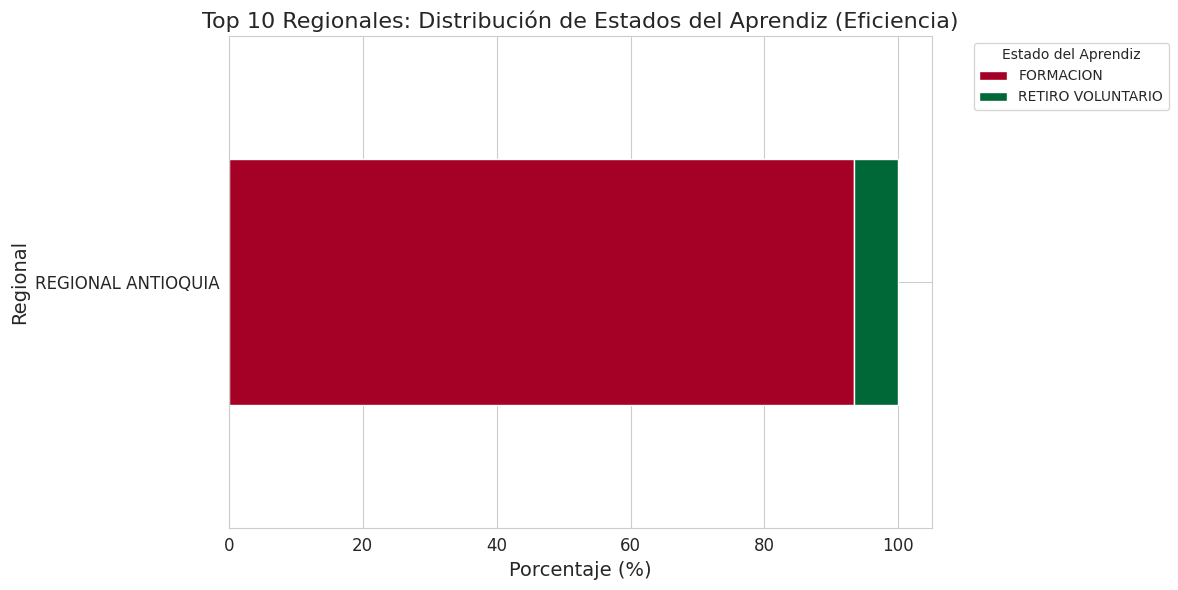

In [ ]:
# --- 1. Eficiencia por Regional: % de Retiro vs. Formación vs. Terminada ---

print("\n--- Análisis de Eficiencia por Regional ---")

# 1. Definir los estados de interés
estados_interes = ['RETIRO VOLUNTARIO', 'FORMACION', 'TERMINADA POR FECHA']

# 2. Filtrar el DataFrame cruzado por estos estados
df_eficiencia = df_cruzado[df_cruzado['ESTADO_APRENDIZ'].isin(estados_interes)].copy()

# 3. Calcular la tabla de contingencia normalizada por REGIONAL
# Normalizar por 'index' (fila) para obtener porcentajes dentro de cada regional
contingency_regional = pd.crosstab(
    df_eficiencia['REGIONAL'],
    df_eficiencia['ESTADO_APRENDIZ'],
    normalize='index'
).mul(100).sort_values(by='RETIRO VOLUNTARIO', ascending=False) # Ordenar por Retiro para ver las más afectadas

# 4. Seleccionar las 10 principales para una visualización clara
top_10_regionales = contingency_regional.head(10)

# Visualización
plt.figure(figsize=(14, 8))
top_10_regionales.plot(
    kind='barh',
    stacked=True,
    colormap='RdYlGn' # Colores que van de malo (rojo) a bueno (verde)
)
plt.title('Top 10 Regionales: Distribución de Estados del Aprendiz (Eficiencia)')
plt.xlabel('Porcentaje (%)')
plt.ylabel('Regional')
plt.legend(title='Estado del Aprendiz', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()